
# Customer Churn Deep Dive & Action Plan

## 1. Project Overview

Customer churn occurs when customers stop using a company's products or services.

This project aims to analyse customer behaviour, identify factors associated with customer churn, predict customers who are at risk of leaving, and develop data-driven customer retention strategies.

## 2. Business Objectives

- Analyse customer churn patterns.
- Identify high-risk customer segments.
- Understand factors associated with churn.
- Build machine learning models.
- Develop customer retention strategies.

## 3. Technology Stack

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SQL
- Scikit-learn
- XGBoost
- SHAP
- Power BI


In [25]:

# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [26]:
# ==========================================
# 2. LOAD CUSTOMER CHURN DATASET
# ==========================================

df = pd.read_csv(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (7043, 21)


In [27]:

# ==========================================
# 3. INITIAL DATA EXPLORATION
# ==========================================

# First five records
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


## 4. Data Quality Analysis

In this section, we investigate the quality of the dataset by checking missing values, duplicate records, incorrect data types, and target variable distribution.

In [28]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values[missing_values > 0])

Missing Values:


Series([], dtype: int64)

In [29]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [30]:
# Number of unique values in each column

print("Unique Values:")
display(df.nunique())

Unique Values:


customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [31]:
# Churn distribution

print("Churn Counts:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


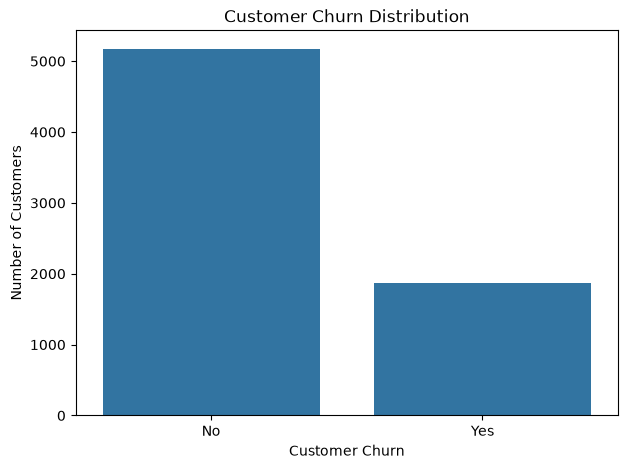

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [33]:
# Check blank or whitespace-only values

blank_values = (
    df.astype("string")
      .apply(lambda col: col.str.strip().eq("").sum())
)

print("Blank values in each column:")
display(blank_values[blank_values > 0])

Blank values in each column:


TotalCharges    11
dtype: int64


### Business Insights – Overall Customer Churn

1. Total customers: 7,043.
2. Customers retained: 5,174 (73.46%).
3. Customers churned: 1,869 (26.54%).

**Key Finding:**

Approximately 26.54% of customers have discontinued the company's services. This indicates a significant customer retention challenge.

**Business Recommendation:**

The company should investigate customer segments, contract types, service usage and pricing patterns to identify the major factors associated with customer churn.

Further analysis is required before recommending specific retention strategies.


## 5. Customer Churn Analysis by Contract Type

The objective is to investigate whether customer contract duration is associated with churn.

In [34]:
# Churn analysis by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


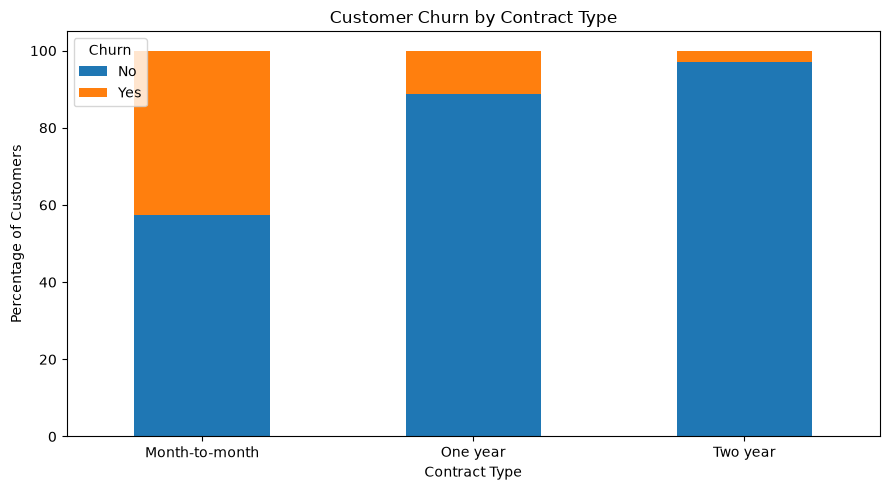

In [35]:
# Visualize churn by contract type

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Business Insights – Churn by Contract Type

**Key Findings:**

1. Month-to-month customers have the highest churn rate at 42.71%.
2. One-year contract customers have a churn rate of 11.27%.
3. Two-year contract customers have the lowest churn rate at 2.83%.

**Business Interpretation:**

Customers with month-to-month contracts are significantly more likely to discontinue services compared with customers having longer-term contracts.

**Possible Business Actions:**

- Introduce incentives for annual contract upgrades.
- Provide loyalty rewards.
- Investigate reasons behind month-to-month customer dissatisfaction.
- Improve retention campaigns for short-term contract customers.

**Conclusion:**

Contract type is an important feature associated with customer churn and should be investigated further during predictive modelling.


## 6. Customer Churn Analysis by Tenure

The objective is to investigate the relationship between customer tenure and churn.

In [36]:
tenure_analysis = df.groupby("Churn")["tenure"].mean()

print("Average Customer Tenure:")
display(tenure_analysis.round(2))

Average Customer Tenure:


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

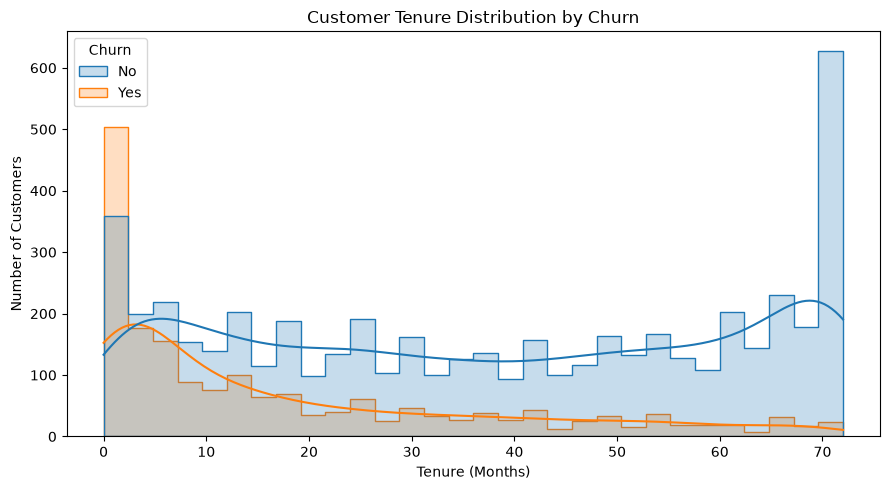

In [37]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


### Business Insights – Customer Churn by Tenure

**Key Findings:**

1. Average tenure of retained customers: 37.57 months.
2. Average tenure of churned customers: 17.98 months.
3. Churned customers have substantially shorter average tenure.

**Business Interpretation:**

Customers with shorter relationships with the company appear more likely to discontinue their services.

The early stages of the customer lifecycle may represent an important retention opportunity.

**Recommended Business Actions:**

- Improve new customer onboarding.
- Introduce engagement campaigns during the first few months.
- Collect feedback from newly acquired customers.
- Identify early dissatisfaction signals.
- Provide targeted support to customers showing signs of disengagement.

**Conclusion:**

Customer tenure is an important feature associated with churn and should be included in predictive modelling.


## 7. Customer Churn Analysis by Monthly Charges

The objective is to investigate whether monthly service charges are associated with customer churn.

In [38]:
charges_analysis = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average Monthly Charges:")
display(charges_analysis.round(2))

Average Monthly Charges:


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

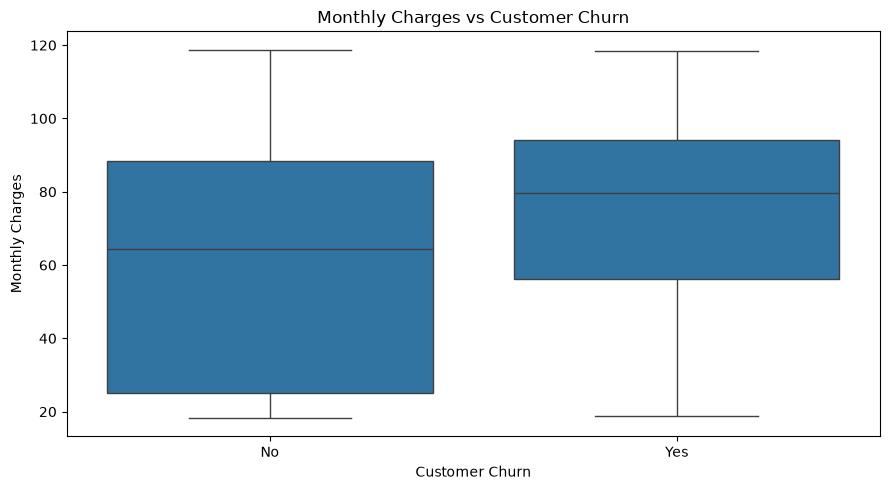

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [40]:
display(
    df.groupby("Churn")["MonthlyCharges"]
      .describe()
      .round(2)
)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35



### Business Insights – Monthly Charges vs Customer Churn

**Key Findings:**

1. Average monthly charges of retained customers: $61.27.
2. Average monthly charges of churned customers: $74.44.
3. Median monthly charges of retained customers: $64.43.
4. Median monthly charges of churned customers: $79.65.

**Business Interpretation:**

Customers who discontinued services had higher average and median monthly charges than customers who remained.

This indicates a possible association between monthly charges and customer churn.

**Recommended Business Actions:**

- Review high-priced service packages.
- Investigate customer satisfaction with expensive plans.
- Introduce targeted retention offers.
- Evaluate pricing and perceived service value.

**Conclusion:**

Monthly charges may be an important factor associated with customer churn. Further analysis is needed to understand its relationship with contract type and other customer characteristics.


## 8. Customer Churn Analysis by Internet Service

In [41]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Internet Service:")
display(internet_churn.round(2))

Churn by Internet Service:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


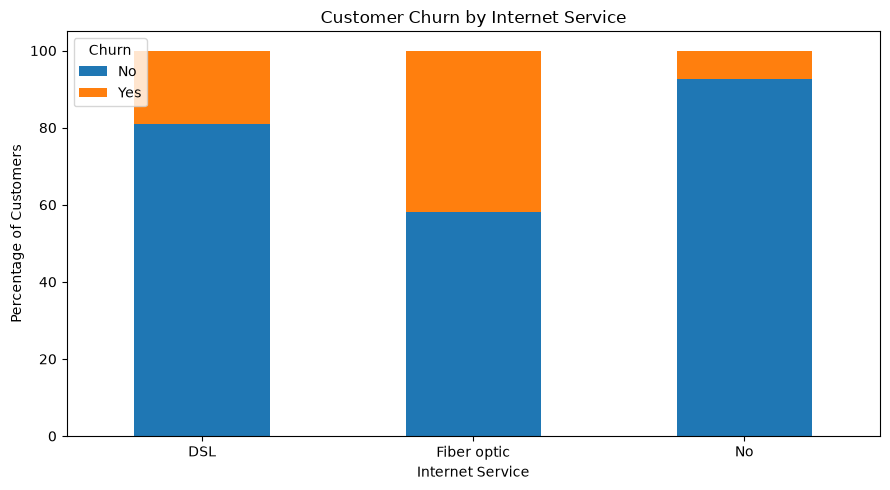

In [42]:
internet_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
display(
    pd.crosstab(
        df["InternetService"],
        df["Churn"]
    )
)

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113



### Business Insights – Customer Churn by Internet Service

**Key Findings:**

1. Fiber optic customers have the highest churn rate at 41.89%.
2. DSL customers have a churn rate of 18.96%.
3. Customers without internet service have the lowest churn rate at 7.40%.
4. Fiber optic has the highest number of churned customers (1,297).

**Business Interpretation:**

Fiber optic customers represent a high-risk customer segment. Their churn rate is significantly higher than that of DSL and customers without internet service.

**Possible Business Actions:**

- Investigate fiber optic pricing.
- Examine service quality and technical complaints.
- Review customer satisfaction.
- Develop targeted retention campaigns for fiber optic customers.

**Conclusion:**

Internet service type is an important feature associated with customer churn. Further investigation is required to identify the underlying reasons for higher fiber optic churn.


## 9. Customer Churn Analysis by Technical Support

In [44]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Technical Support:")
display(support_churn.round(2))

Churn by Technical Support:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


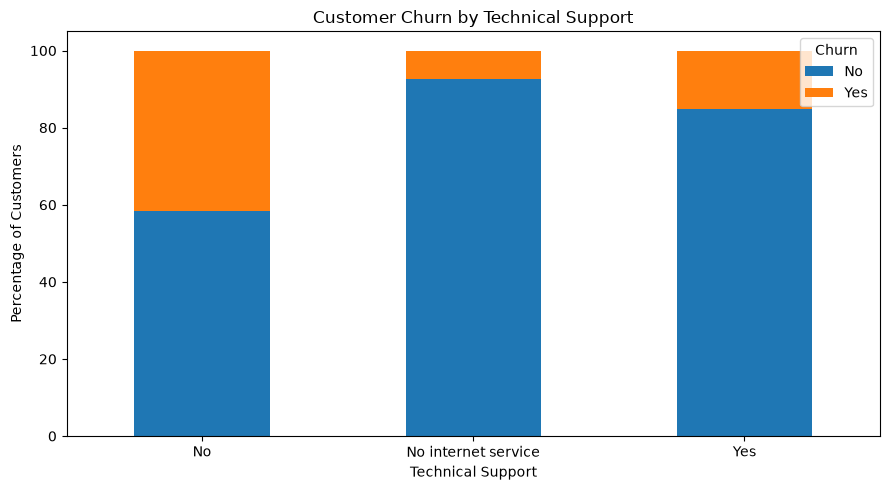

In [45]:
support_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
display(
    pd.crosstab(
        df["TechSupport"],
        df["Churn"]
    )
)

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310



### Business Insights – Customer Churn by Technical Support

**Key Findings:**

1. Customers without technical support have a churn rate of 41.64%.
2. Customers with technical support have a churn rate of 15.17%.
3. A total of 1,446 customers without technical support churned.
4. Only 310 customers with technical support churned.

**Business Interpretation:**

Customers without technical support demonstrate a significantly higher churn rate. Technical support availability may be an important factor associated with customer retention.

**Business Recommendations:**

- Encourage customers to subscribe to technical support.
- Improve customer assistance and issue resolution.
- Identify customers experiencing repeated technical difficulties.
- Develop targeted retention campaigns.

**Conclusion:**

Technical support availability is an important factor to investigate when identifying customer churn patterns.


## 10. Customer Churn Analysis by Payment Method

In [47]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Payment Method:")
display(payment_churn.round(2))

Churn by Payment Method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


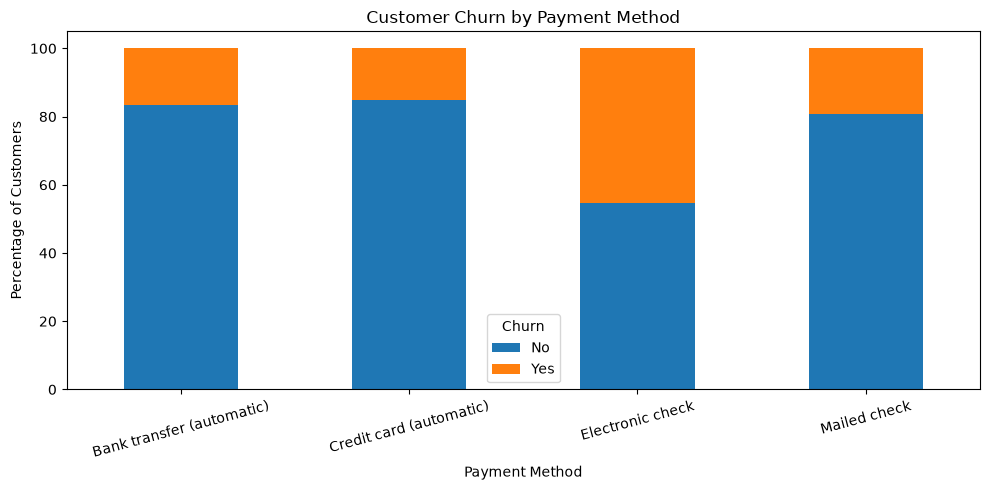

In [48]:
payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [49]:
display(
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"]
    )
)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308



### Business Insights – Customer Churn by Payment Method

**Key Findings:**

1. Electronic check users have the highest churn rate at 45.29%.
2. Credit card automatic users have the lowest churn rate at 15.24%.
3. 1,071 electronic check customers have churned.
4. Automatic payment methods show comparatively lower churn rates.

**Business Interpretation:**

Customers using electronic checks demonstrate significantly higher churn than customers using automatic payment methods.

**Business Recommendations:**

- Encourage customers to adopt automatic payment methods.
- Investigate potential payment-related friction.
- Offer convenient billing options.
- Target electronic check customers with retention campaigns.

**Conclusion:**

Payment method is an important variable to investigate when identifying customer churn patterns.


## 11. Customer Churn Analysis by Online Security

In [50]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Online Security:")
display(security_churn.round(2))

Churn by Online Security:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


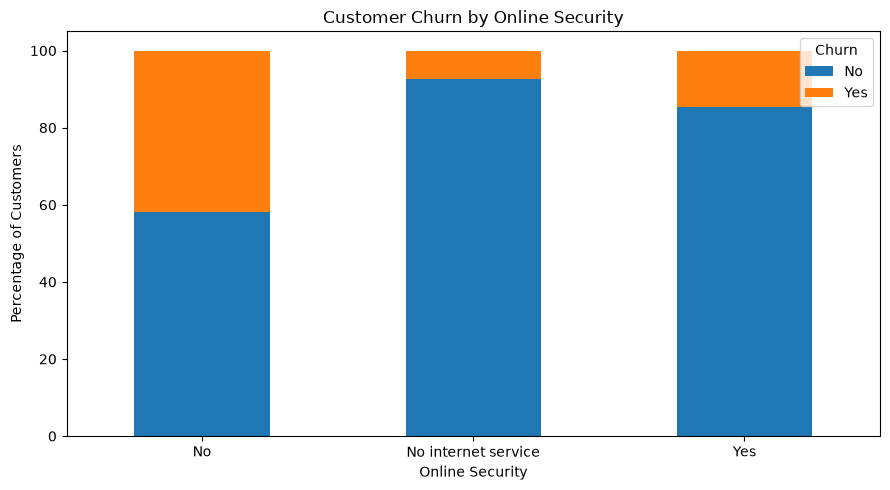

In [51]:
security_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [52]:
display(
    pd.crosstab(
        df["OnlineSecurity"],
        df["Churn"]
    )
)

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295



### Business Insights – Customer Churn by Online Security

**Key Findings:**

1. Customers without online security have the highest churn rate of 41.77%.
2. Customers with online security have a churn rate of only 14.61%.
3. A total of 1,461 customers without online security have churned.
4. Customers subscribing to online security demonstrate better retention.

**Business Interpretation:**

Online security subscription is associated with a significantly lower customer churn rate. Customers without this service represent an important segment for retention analysis.

**Business Recommendations:**

- Promote online security subscriptions.
- Introduce bundled service packages.
- Target customers without online security through personalized retention campaigns.
- Improve awareness about additional service benefits.

**Conclusion:**

Online security is an important customer service feature associated with customer retention.



## 12. Customer Churn Analysis by Online Backup

In [53]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Online Backup:")
display(backup_churn.round(2))

Churn by Online Backup:


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


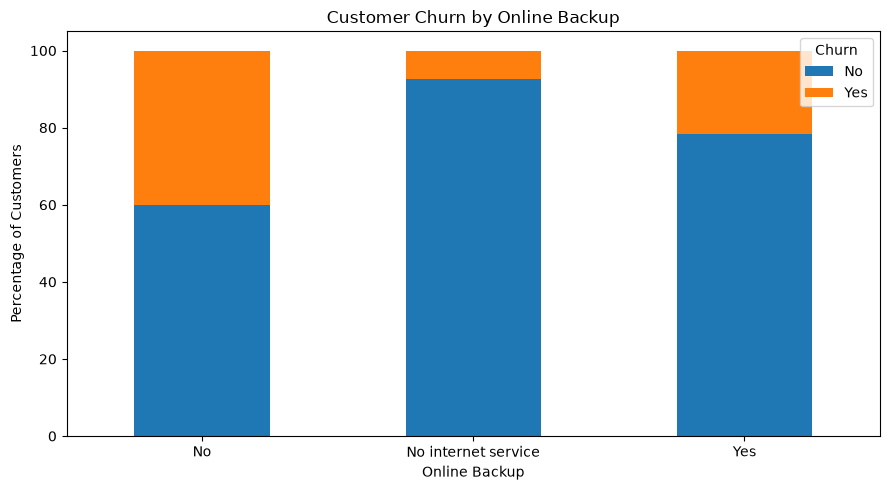

In [54]:
backup_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
display(
    pd.crosstab(
        df["OnlineBackup"],
        df["Churn"]
    )
)

Churn,No,Yes
OnlineBackup,,
No,1855,1233
No internet service,1413,113
Yes,1906,523



### Business Insights – Customer Churn by Online Backup

**Key Findings:**

1. Customers without online backup have a churn rate of 39.93%.
2. Customers with online backup have a churn rate of 21.53%.
3. A total of 1,233 customers without online backup have churned.
4. Customers subscribing to online backup demonstrate comparatively better retention.

**Business Interpretation:**

Online backup subscription is associated with lower customer churn. Customers without this service represent an important segment for retention analysis.

**Business Recommendations:**

- Promote online backup subscriptions.
- Introduce bundled service packages.
- Offer personalized retention campaigns to customers without online backup.
- Educate customers about the benefits of online backup services.

**Conclusion:**

Online backup is another service feature associated with customer retention and should be considered during churn analysis.


## 13. Customer Churn Analysis by Device Protection


In [56]:
device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Device Protection:")
display(device_churn.round(2))

Churn by Device Protection:


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


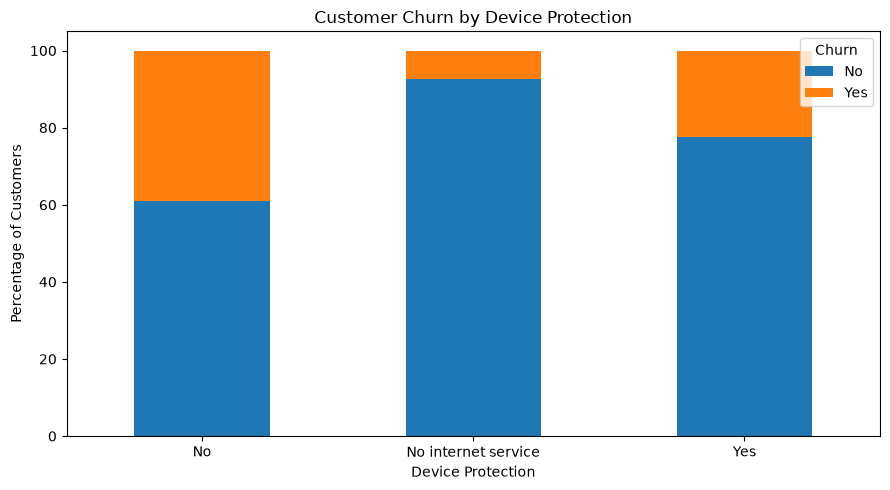

In [57]:
device_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [58]:
display(
    pd.crosstab(
        df["DeviceProtection"],
        df["Churn"]
    )
)

Churn,No,Yes
DeviceProtection,,
No,1884,1211
No internet service,1413,113
Yes,1877,545



### Business Insights

**Key Findings:**

- Customers without Device Protection have a high churn rate of 39.13%.
- Customers with Device Protection have a lower churn rate of 22.50%.
- Customers with no internet service show the lowest churn rate of 7.40%.
- Customers subscribing to Device Protection appear more likely to remain with the company.

### Business Recommendations

- Encourage customers without Device Protection to subscribe through discounts and bundled offers.
- Introduce personalized protection plans for high-risk customers.
- Highlight the benefits of Device Protection during customer onboarding.
- Target customers without Device Protection through retention campaigns.

### Expected Business Outcome

Increasing Device Protection adoption may help reduce customer churn, improve customer satisfaction, and strengthen long-term customer retention.


## 14. Customer Churn Analysis by Streaming TV


In [62]:

tv_churn = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Streaming TV:")
display(tv_churn.round(2))


Churn by Streaming TV:


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


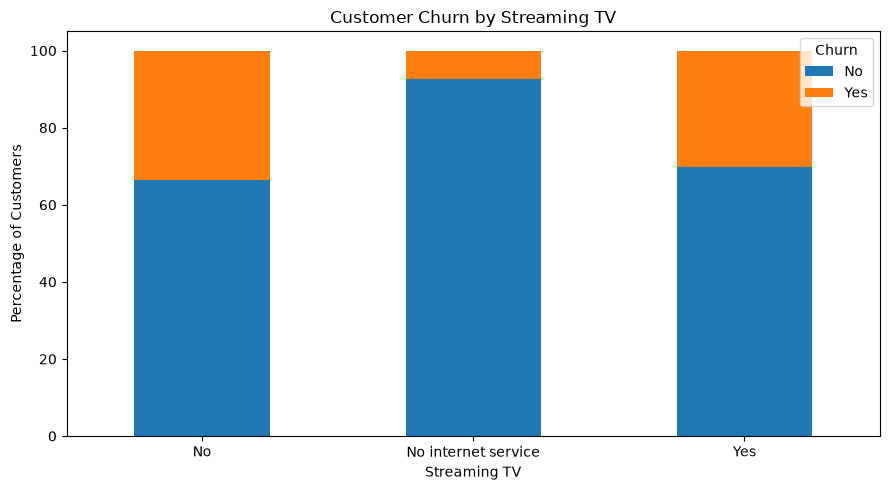

In [63]:

tv_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [64]:

display(
    pd.crosstab(
        df["StreamingTV"],
        df["Churn"]
    )
)


Churn,No,Yes
StreamingTV,,
No,1868,942
No internet service,1413,113
Yes,1893,814


### Business Insights

1. Customers who do not have Streaming TV show the highest churn rate of 33.52%.

2. Customers who have Streaming TV have a churn rate of 30.07%, which is slightly lower than customers without the service.

3. Customers with no internet service have the lowest churn rate of 7.40%.

4. The actual customer counts show that 942 customers without Streaming TV and 814 customers with Streaming TV have churned.

5. Streaming TV subscription alone does not appear to be a strong factor in reducing customer churn.

### Business Recommendation

The company should investigate other factors influencing churn among Streaming TV users, such as contract type, monthly charges, and customer support. Streaming TV can be considered as part of a broader customer retention strategy.

## 15. Customer Churn Analysis by Streaming Movies

In [65]:
movies_churn = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Streaming Movies:")
display(movies_churn.round(2))

Churn by Streaming Movies:


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


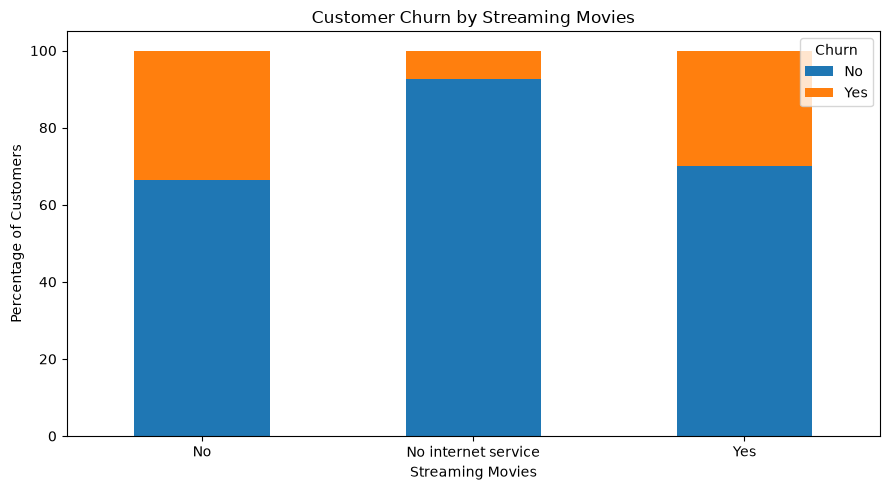

In [66]:
movies_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [67]:
print("Actual Customer Counts:")
display(
    pd.crosstab(
        df["StreamingMovies"],
        df["Churn"]
    )
)

Actual Customer Counts:


Churn,No,Yes
StreamingMovies,,
No,1847,938
No internet service,1413,113
Yes,1914,818


### Business Insights

1. Customers who do not have Streaming Movies show a churn rate of 33.68%.

2. Customers who have Streaming Movies show a slightly lower churn rate of 29.94%.

3. Customers with no internet service have the lowest churn rate of 7.40%.

4. In actual numbers, 938 customers without Streaming Movies and 818 customers with Streaming Movies have churned.

5. The churn rates are relatively close for customers with and without Streaming Movies. This suggests that Streaming Movies subscription alone may not have a strong impact on customer retention.

### Business Recommendation

The company should investigate other factors such as contract type, monthly charges, tenure, and customer support to understand why customers leave. Streaming Movies can be considered as an additional service, but should not be treated as a standalone retention solution.

## 16. Customer Churn Analysis by Number of Services

In [68]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = (
    df[service_columns] == "Yes"
).sum(axis=1)

print("Number of Services:")
display(df["TotalServices"].value_counts().sort_index())

Number of Services:


TotalServices
0      80
1    1701
2    1188
3     965
4     922
5     908
6     676
7     395
8     208
Name: count, dtype: int64

In [69]:
services_churn = pd.crosstab(
    df["TotalServices"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Number of Services:")
display(services_churn.round(2))

Churn by Number of Services:


Churn,No,Yes
TotalServices,,
0,56.25,43.75
1,78.89,21.11
2,67.17,32.83
3,63.52,36.48
4,68.66,31.34
5,74.45,25.55
6,77.51,22.49
7,87.59,12.41
8,94.71,5.29


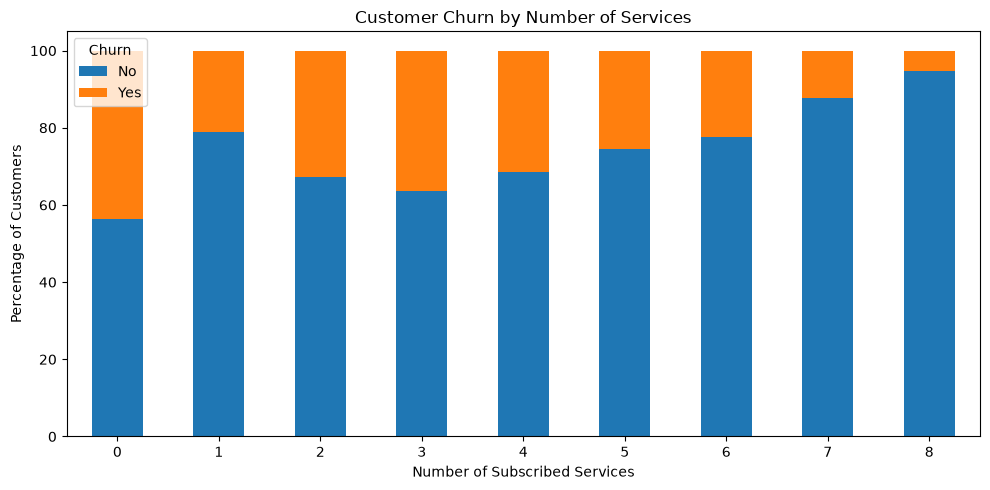

In [70]:
services_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Customer Churn by Number of Services")
plt.xlabel("Number of Subscribed Services")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [71]:
print("Actual Customer Counts:")
display(
    pd.crosstab(
        df["TotalServices"],
        df["Churn"]
    )
)

Actual Customer Counts:


Churn,No,Yes
TotalServices,,
0,45,35
1,1342,359
2,798,390
3,613,352
4,633,289
5,676,232
6,524,152
7,346,49
8,197,11


### Business Insights

1. Customers using 0 services have the highest churn rate of 43.75%, followed by customers using 3 services at 36.48%.

2. Customers using only 1 service have a churn rate of 21.11%.

3. Churn generally decreases as the number of subscribed services increases. Customers using 7 services have a churn rate of 12.41%, while customers using all 8 services have the lowest churn rate of 5.29%.

4. In actual numbers, 359 customers using 1 service and 390 customers using 2 services have churned. These are important customer groups because they contribute a considerable number of churned customers.

5. The results suggest that customers subscribed to more services tend to have better retention, although the pattern is not perfectly consistent across every service count.

### Business Recommendation

The company should focus on customers using fewer services by offering relevant service bundles, personalized upgrades, and loyalty benefits. These initiatives may improve customer engagement and retention.

Customers using only 1 or 2 services should be prioritized because they represent a substantial number of churned customers.

## 17. Customer Churn Analysis by Senior Citizen

In [72]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Senior Citizen:")
display(senior_churn.round(2))

Churn by Senior Citizen:


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


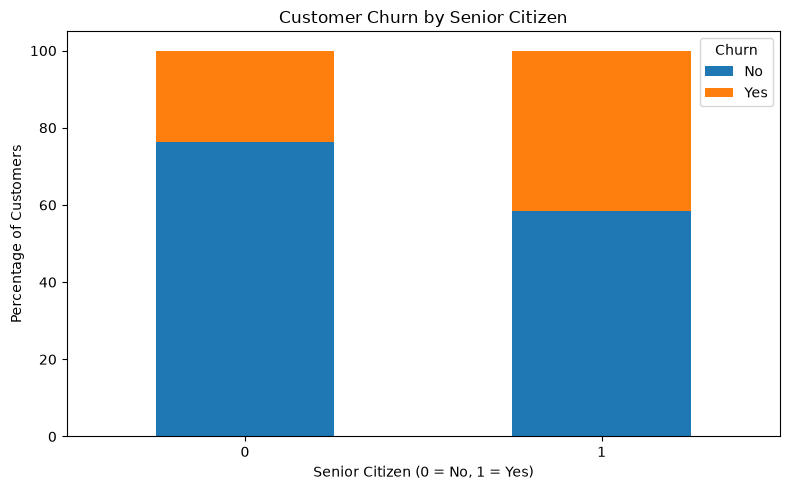

In [73]:
senior_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Customer Churn by Senior Citizen")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [74]:
print("Actual Customer Counts:")
display(
    pd.crosstab(
        df["SeniorCitizen"],
        df["Churn"]
    )
)

Actual Customer Counts:


Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


### Business Insights

1. Senior citizens have a churn rate of 41.68%, which is significantly higher than non-senior citizens, whose churn rate is 23.61%.

2. Non-senior citizens show better retention, with 76.39% of customers staying with the company.

3. Among senior citizens, 476 customers have churned, while 666 have remained.

4. Among non-senior citizens, 1,393 customers have churned, compared to 4,508 retained customers.

5. Although senior citizens have a smaller customer base, their churn rate is considerably higher. This indicates that they may require additional attention from the retention team.

### Business Recommendation

The company should introduce personalized retention strategies for senior citizens, including dedicated customer support, simplified service plans, and targeted loyalty offers.

Regular follow-ups can help identify their concerns and improve customer satisfaction.

## 18. Customer Churn Analysis by Partner Status

In [75]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Partner Status:")
display(partner_churn.round(2))

Churn by Partner Status:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


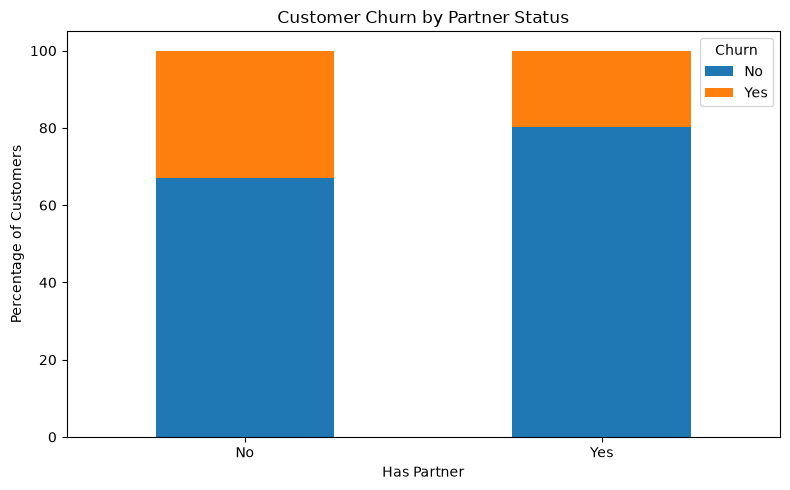

In [76]:
partner_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [77]:
print("Actual Customer Counts:")
display(
    pd.crosstab(
        df["Partner"],
        df["Churn"]
    )
)

Actual Customer Counts:


Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


### Business Insights

1. Customers without a partner have a churn rate of 32.96%, whereas customers with a partner have a lower churn rate of 19.66%.

2. Customers with a partner show better retention, with 80.34% staying with the company compared to 67.04% of customers without a partner.

3. In actual numbers, 1,200 customers without a partner have churned, compared to 669 customers with a partner.

4. Customers without partners appear more likely to leave the company. This suggests that partner status may be associated with customer retention.

### Business Recommendation

The company should give additional attention to customers without partners through personalized offers, loyalty benefits, and regular engagement.

Retention campaigns should also consider other factors such as tenure, contract type, and monthly charges before targeting customers.

## 19. Customer Churn Analysis by Dependents

In [78]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Dependents:")
display(dependents_churn.round(2))

Churn by Dependents:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


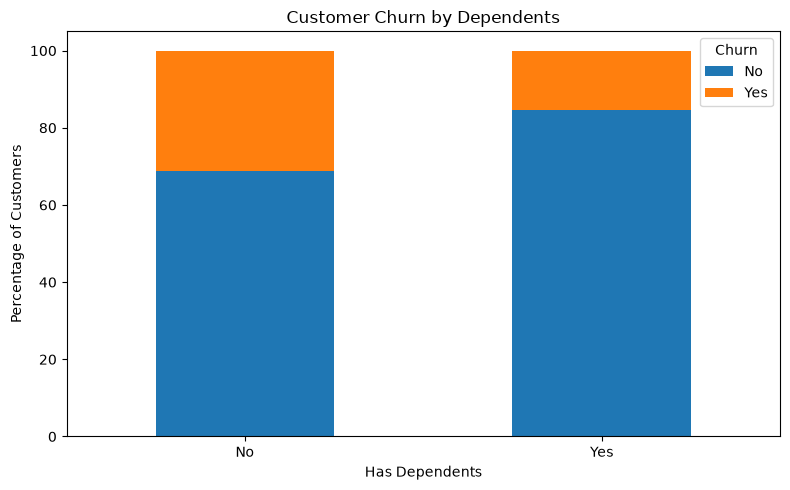

In [79]:
dependents_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Customer Churn by Dependents")
plt.xlabel("Has Dependents")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [80]:
print("Actual Customer Counts:")
display(
    pd.crosstab(
        df["Dependents"],
        df["Churn"]
    )
)

Actual Customer Counts:


Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


### Business Insights

1. Customers without dependents have a churn rate of 31.28%, whereas customers with dependents have a significantly lower churn rate of 15.45%.

2. Customers with dependents show better retention, with 84.55% staying with the company compared to 68.72% of customers without dependents.

3. In actual numbers, 1,543 customers without dependents have churned, compared to only 326 customers with dependents.

4. Customers without dependents represent a larger churn group and may require more focused retention strategies.

5. Having dependents appears to be associated with better customer retention, although this analysis alone does not establish a causal relationship.

### Business Recommendation

The company should prioritize retention campaigns for customers without dependents through personalized offers, loyalty rewards, and flexible service plans.

Customer retention strategies should also consider contract type, tenure, and monthly charges to identify customers at higher risk of leaving.

## 20. Customer Churn Analysis by Combined Demographic Factors

In [81]:
demographic_churn = pd.crosstab(
    [
        df["SeniorCitizen"],
        df["Partner"],
        df["Dependents"]
    ],
    df["Churn"],
    normalize="index"
) * 100

print("Churn by Combined Demographic Factors:")
display(demographic_churn.round(2))

Churn by Combined Demographic Factors:


Churn                                No    Yes
SeniorCitizen Partner Dependents              
0             No      No          68.85  31.15
                      Yes         78.75  21.25
              Yes     No          79.19  20.81
                      Yes         86.25  13.75
1             No      No          50.80  49.20
                      Yes         75.00  25.00
              Yes     No          63.67  36.33
                      Yes         75.90  24.10

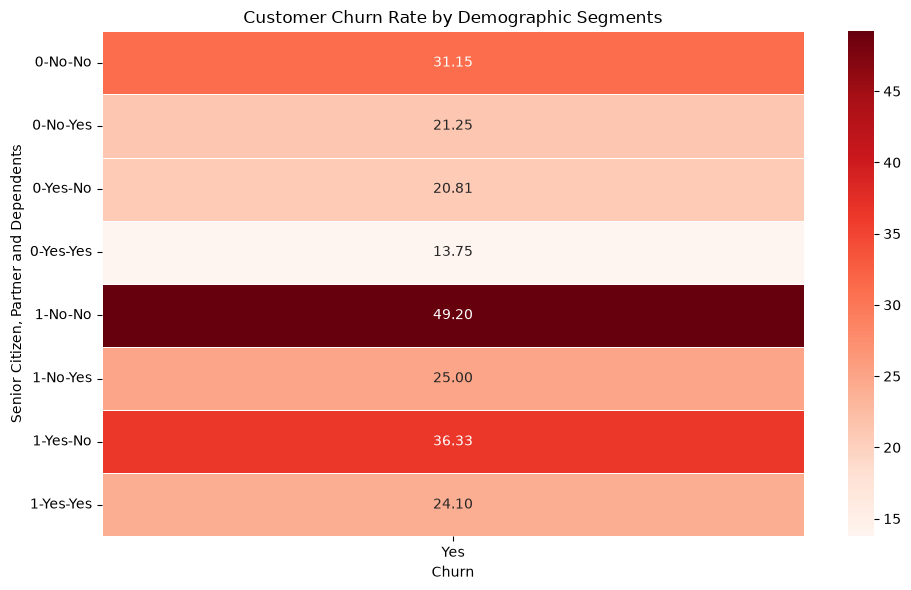

In [82]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    demographic_churn[["Yes"]],
    annot=True,
    fmt=".2f",
    cmap="Reds",
    linewidths=0.5
)

plt.title("Customer Churn Rate by Demographic Segments")
plt.xlabel("Churn")
plt.ylabel("Senior Citizen, Partner and Dependents")

plt.tight_layout()
plt.show()

In [83]:
print("Actual Customer Counts:")

demographic_counts = pd.crosstab(
    [
        df["SeniorCitizen"],
        df["Partner"],
        df["Dependents"]
    ],
    df["Churn"]
)

display(demographic_counts)

Actual Customer Counts:


Churn                               No  Yes
SeniorCitizen Partner Dependents           
0             No      No          1872  847
                      Yes          278   75
              Yes     No           921  242
                      Yes         1437  229
1             No      No           285  276
                      Yes            6    2
              Yes     No           312  178
                      Yes           63   20

In [84]:
highest_churn_segments = demographic_churn.sort_values(
    by="Yes",
    ascending=False
)

print("Top 5 Demographic Segments with Highest Churn:")
display(highest_churn_segments.head(5).round(2))

Top 5 Demographic Segments with Highest Churn:


Churn                                No    Yes
SeniorCitizen Partner Dependents              
1             No      No          50.80  49.20
              Yes     No          63.67  36.33
0             No      No          68.85  31.15
1             No      Yes         75.00  25.00
              Yes     Yes         75.90  24.10

### Business Insights

1. Senior citizens without a partner and without dependents have the highest churn rate of 49.20%.

2. Non-senior citizens without a partner and without dependents have a churn rate of 31.15%.

3. Senior citizens with a partner but without dependents show a churn rate of 36.33%.

4. Non-senior citizens with a partner and dependents have the lowest churn rate of 13.75%.

5. The actual customer counts show that 276 senior citizens without a partner and without dependents have churned, compared to 285 retained customers in the same segment.

6. Overall, the analysis suggests that senior citizen status, partner status, and dependents together can help identify customer segments with higher churn risk.

### Business Recommendation

The company should prioritize senior citizens who do not have a partner or dependents through personalized retention campaigns, dedicated customer support, and suitable service packages.

Customers belonging to high-churn demographic segments should be monitored more closely. However, demographic factors should be combined with tenure, contract type, and monthly charges before making retention decisions.
### Additional Finding

The top 5 demographic segments confirm that senior citizens without partners have relatively high churn rates, particularly those without dependents.

The highest-risk segment is senior citizens without a partner and without dependents, with a churn rate of 49.20%.

## 21. Correlation Analysis of Numerical Features

In [85]:
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values
print("Missing values in TotalCharges:")
print(df["TotalCharges"].isnull().sum())

Missing values in TotalCharges:
11


In [86]:
# Select numerical columns
numerical_df = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
MonthlyCharges,0.22,0.25,1.00,0.65
TotalCharges,0.10,0.83,0.65,1.00


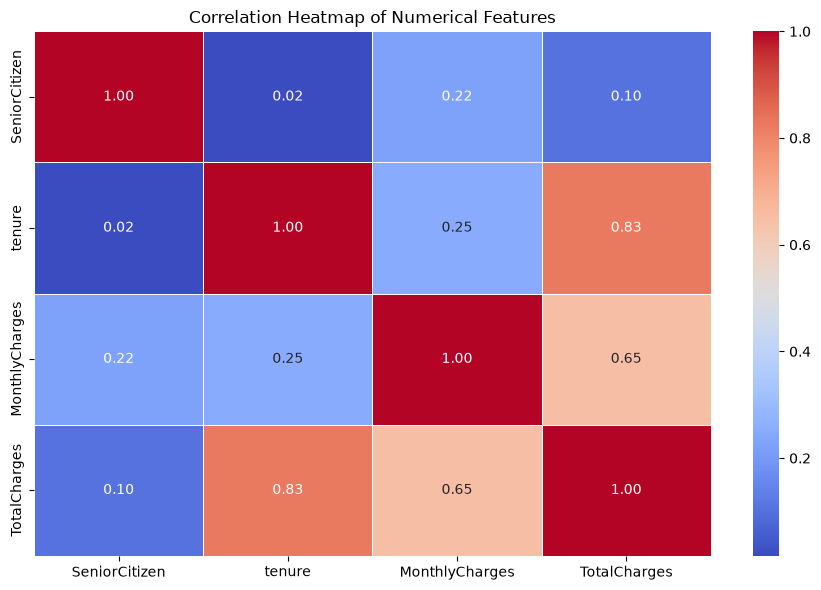

In [87]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Business Insights

1. Tenure and TotalCharges have a strong positive correlation of 0.83. This indicates that customers who stay longer generally accumulate higher total charges.

2. MonthlyCharges and TotalCharges have a positive correlation of 0.65, suggesting that customers with higher monthly bills tend to accumulate higher total charges.

3. Tenure and MonthlyCharges have a weak positive correlation of 0.25.

4. SeniorCitizen has a very weak correlation with tenure (0.02) and TotalCharges (0.10).

5. The correlation between SeniorCitizen and MonthlyCharges is 0.22, indicating a weak positive relationship.

6. Overall, tenure and monthly charges show stronger relationships with accumulated customer charges compared to senior citizen status.

### Business Recommendation

The company should pay attention to customer tenure and billing patterns while designing retention strategies.

Customers with high monthly charges and shorter tenure may need additional attention through personalized plans, discounts, and loyalty offers.

### Important Observation

Correlation does not imply causation. These relationships describe numerical feature associations and do not directly measure their relationship with customer churn.

## 22. Data Preprocessing

In [88]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nData Types:")
display(df.dtypes)

Dataset Shape: (7043, 22)

Missing Values:


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TotalServices        0
dtype: int64


Data Types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
TotalServices         int64
dtype: object

In [89]:
# Fill missing TotalCharges using median
median_total_charges = df["TotalCharges"].median()

df["TotalCharges"] = df["TotalCharges"].fillna(
    median_total_charges
)

print("Missing values after treatment:")
print(df["TotalCharges"].isnull().sum())

Missing values after treatment:
0


In [90]:
df = df.drop(columns=["customerID"])

print("Dataset shape after dropping customerID:")
print(df.shape)

Dataset shape after dropping customerID:
(7043, 21)


In [91]:
print("Churn Distribution:")
display(df["Churn"].value_counts())

print("\nChurn Percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Churn Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn Percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [92]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Encoded Churn Values:")
display(df["Churn"].value_counts())

Encoded Churn Values:


Churn
0    5174
1    1869
Name: count, dtype: int64

In [93]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDataset Information:")
df.info()

Final Dataset Shape: (7043, 21)

Missing Values:
0

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-

In [94]:
# Separate categorical and numerical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove target column from numerical features
numerical_columns.remove("Churn")

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']


C:\Users\hp\AppData\Local\Temp\ipykernel_822944\1105132806.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [95]:
# Features
X = df.drop(columns=["Churn"])

# Target
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 20)
Target Shape: (7043,)


In [96]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training Features: (5634, 20)
Testing Features: (1409, 20)

Training Target Distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


Testing Target Distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

# Fit on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

Encoded Training Shape: (5634, 46)
Encoded Testing Shape: (1409, 46)


In [98]:
print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

print("\nTarget distribution in training data:")
print(y_train.value_counts())

print("\nTarget distribution in testing data:")
print(y_test.value_counts())

Training data shape: (5634, 46)
Testing data shape: (1409, 46)

Target distribution in training data:
Churn
0    4139
1    1495
Name: count, dtype: int64

Target distribution in testing data:
Churn
0    1035
1     374
Name: count, dtype: int64


## 23. Machine Learning Model Training

In this section, multiple machine learning classification algorithms will be trained to predict customer churn.

The following models will be evaluated:
- Logistic Regression
- Random Forest Classifier
- XGBoost Classifier

The models will be compared using accuracy, precision, recall, F1-score, and ROC-AUC.

In [99]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [100]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train_encoded, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [101]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_encoded, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [102]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train)

print("XGBoost Training Completed!")

XGBoost Training Completed!


## 24. Model Evaluation and Comparison

In this section, the performance of Logistic Regression, Random Forest, and XGBoost models is evaluated using multiple classification metrics.

The evaluation metrics include:
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

These metrics help compare the predictive performance of all three models.

In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_encoded)
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8415
1,Random Forest,0.7615,0.5440,0.6283,0.5831,0.8188
2,XGBoost,0.7999,0.6575,0.5134,0.5766,0.8419


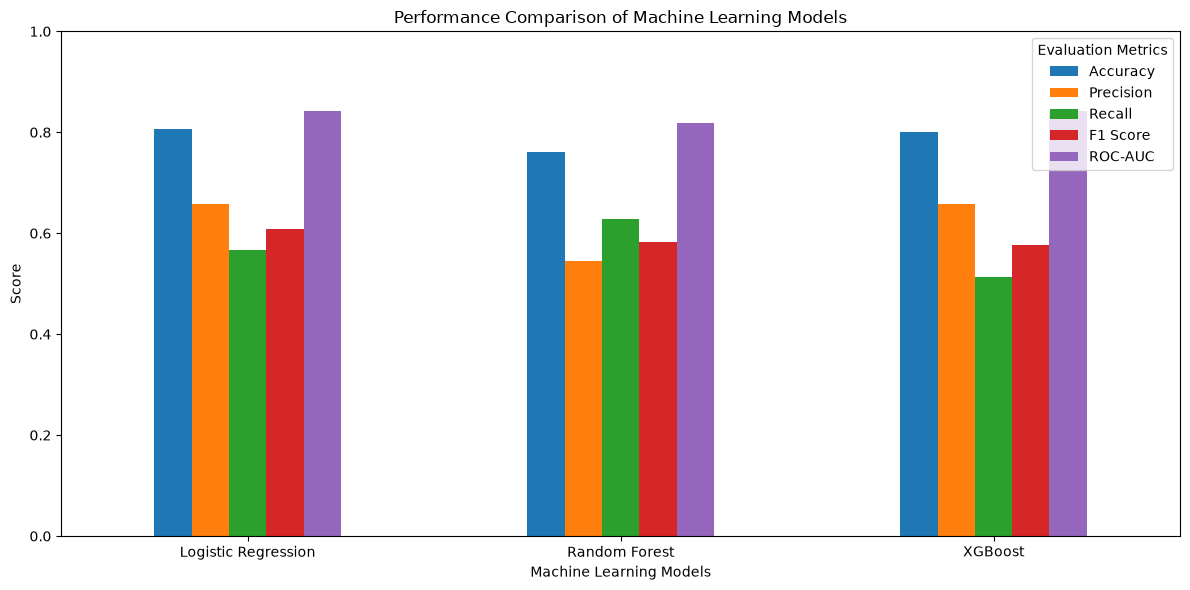

In [109]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

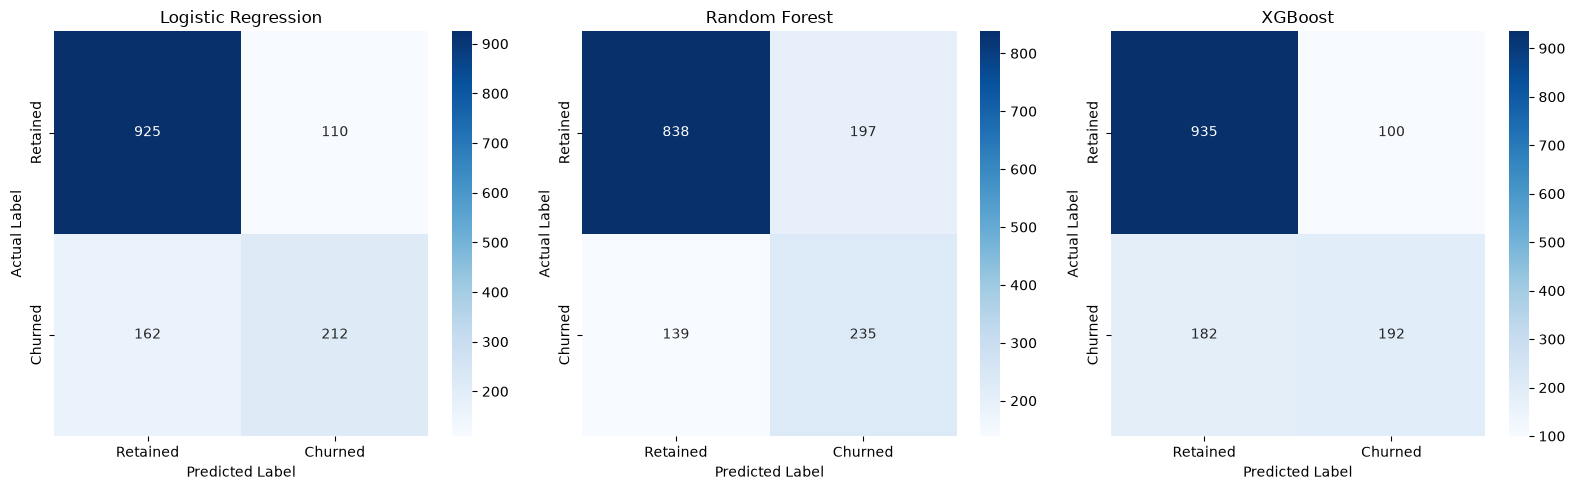

In [110]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test_encoded)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Retained", "Churned"],
        yticklabels=["Retained", "Churned"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Model Evaluation Insights

1. Logistic Regression achieved an accuracy of 80.70%, precision of 65.84%, recall of 56.68%, and F1-score of 60.92%.

2. Random Forest achieved an accuracy of 76.15% and the highest recall of 62.83% among the three models.

3. XGBoost achieved an accuracy of 79.99% and the highest ROC-AUC score of 84.19%.

4. Random Forest correctly identified 235 churned customers, compared to 212 for Logistic Regression and 192 for XGBoost.

5. All three models demonstrate the ability to identify customer churn patterns, but their performance differs across evaluation metrics.

### Conclusion

The evaluation highlights different strengths of the three machine learning models. Further explainability analysis will help understand which customer features contribute to churn predictions.

## 25. Final Model Selection and Justification

### Final Model Selection: Random Forest Classifier

Based on the evaluation of Logistic Regression, Random Forest, and XGBoost, Random Forest was selected as the final model for customer churn prediction.

### Reasons for Selection

1. Random Forest achieved the highest recall of 62.83% among all three models.

2. It correctly identified 235 actual churned customers, compared to 212 for Logistic Regression and 192 for XGBoost.

3. It had the lowest number of missed churned customers (139), making it more suitable for identifying customers at risk of leaving.

4. Although Logistic Regression achieved higher accuracy and precision, Random Forest better supports the primary business objective of identifying potential churners.

### Final Decision

Random Forest was selected because identifying customers who are likely to leave is the primary objective of this project. Its higher recall makes it suitable for supporting targeted customer retention strategies.

However, its higher number of false positives should also be considered when planning retention campaigns.

## 26. Save Final Model and Preprocessing Pipeline

The selected Random Forest model and the fitted preprocessing pipeline are saved for future use. This allows us to make predictions on new customer data without retraining the model or fitting the preprocessing steps again.

In [121]:
import joblib
import os

In [122]:
# Create the path for saving the model
os.makedirs("../models", exist_ok=True)

# Store model and preprocessing components together
model_artifact = {
    "model": random_forest_model,
    "preprocessor": preprocessor,
    "feature_names": feature_names,
    "target_mapping": {"No": 0, "Yes": 1}
}

# Save the complete artifact
joblib.dump(model_artifact, "../models/customer_churn_model.pkl")

print("Model and preprocessing pipeline saved successfully!")

Model and preprocessing pipeline saved successfully!


In [123]:
model_path = "../models/customer_churn_model.pkl"

if os.path.exists(model_path):
    print("File exists:", model_path)
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found!")

File exists: ../models/customer_churn_model.pkl
File size: 39658.67 KB


## 27. Testing the Saved Model

The saved model artifact is loaded to verify that the model and preprocessing pipeline were stored correctly. Predictions from the loaded model are compared with the original trained model to ensure consistency.

In [124]:
# Load the saved model artifact
loaded_artifact = joblib.load("../models/customer_churn_model.pkl")

# Extract model and preprocessing pipeline
loaded_model = loaded_artifact["model"]
loaded_preprocessor = loaded_artifact["preprocessor"]

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [125]:
# Transform test data using the saved preprocessing pipeline
X_test_saved = loaded_preprocessor.transform(X_test)

# Generate predictions using the loaded model
saved_predictions = loaded_model.predict(X_test_saved)

# Generate predictions using the original trained model
original_predictions = random_forest_model.predict(X_test_encoded)

print("Predictions generated successfully!")

Predictions generated successfully!


In [126]:
# Check whether both models produce identical predictions
comparison = (saved_predictions == original_predictions)

print("Total test samples:", len(comparison))
print("Matching predictions:", comparison.sum())
print("All predictions match:", comparison.all())

Total test samples: 1409
Matching predictions: 1409
All predictions match: True


## 28. SHAP Explainability

SHAP (SHapley Additive exPlanations) is an explainability technique used to understand how individual features contribute to machine learning predictions.

It helps identify:
- Most influential features in customer churn prediction.
- Features that increase or decrease churn predictions.
- How individual customer characteristics influence model predictions.

In [111]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP Version:", shap.__version__)

SHAP Version: 0.54.1


In [112]:
feature_names = preprocessor.get_feature_names_out()

print("Total Encoded Features:", len(feature_names))
print("\nEncoded Feature Names:")
print(feature_names)

Total Encoded Features: 46

Encoded Feature Names:
['categorical__gender_Female' 'categorical__gender_Male'
 'categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__OnlineBackup_No'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes' 'categorical__DeviceProtection_No'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__Strea

In [113]:
X_train_shap = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_shap = pd.DataFrame(
    X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

print("SHAP Training Data Shape:", X_train_shap.shape)
print("SHAP Testing Data Shape:", X_test_shap.shape)

SHAP Training Data Shape: (5634, 46)
SHAP Testing Data Shape: (1409, 46)


In [114]:
explainer = shap.TreeExplainer(random_forest_model)

shap_values = explainer.shap_values(X_test_shap)

print("SHAP values generated successfully!")

SHAP values generated successfully!


In [115]:
# Check SHAP output format
if isinstance(shap_values, list):
    shap_values_churn = shap_values[1]

elif hasattr(shap_values, "values"):
    shap_values_churn = shap_values.values

else:
    shap_values_churn = shap_values

# Select churn class if output contains multiple classes
if shap_values_churn.ndim == 3:
    shap_values_churn = shap_values_churn[:, :, 1]

print("SHAP Values Shape:", shap_values_churn.shape)
print("Testing Data Shape:", X_test_shap.shape)

SHAP Values Shape: (1409, 46)
Testing Data Shape: (1409, 46)


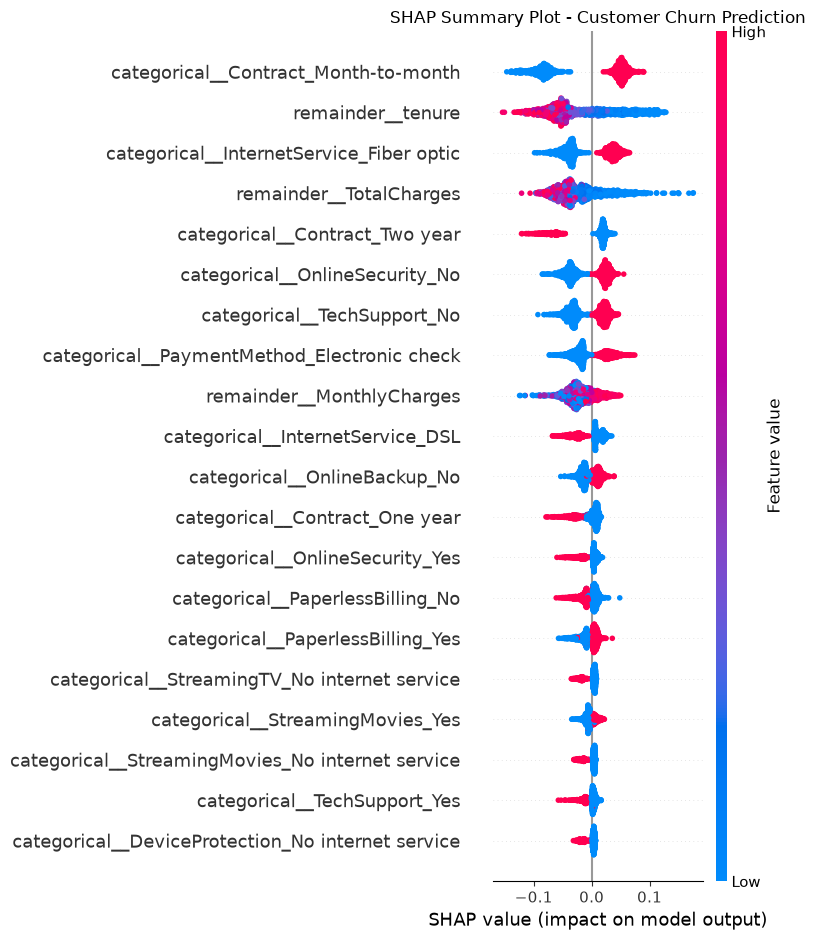

In [116]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_churn,
    X_test_shap,
    show=False
)

plt.title("SHAP Summary Plot - Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [117]:
# Calculate mean absolute SHAP values
shap_importance = pd.DataFrame({
    "Feature": X_test_shap.columns,
    "Importance": np.abs(shap_values_churn).mean(axis=0)
})

# Sort features by importance
shap_importance = shap_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(shap_importance.head(15).round(4))

Top 15 Important Features:


,Feature,Importance
32,categorical__Contract_Month-to-month,0.0681
42,remainder__tenure,0.0559
12,categorical__InternetService_Fiber optic,0.0399
44,remainder__TotalCharges,0.0395
34,categorical__Contract_Two year,0.0323
14,categorical__OnlineSecurity_No,0.0314
23,categorical__TechSupport_No,0.0285
39,categorical__PaymentMethod_Electronic check,0.0263
43,remainder__MonthlyCharges,0.0253
11,categorical__InternetService_DSL,0.0189


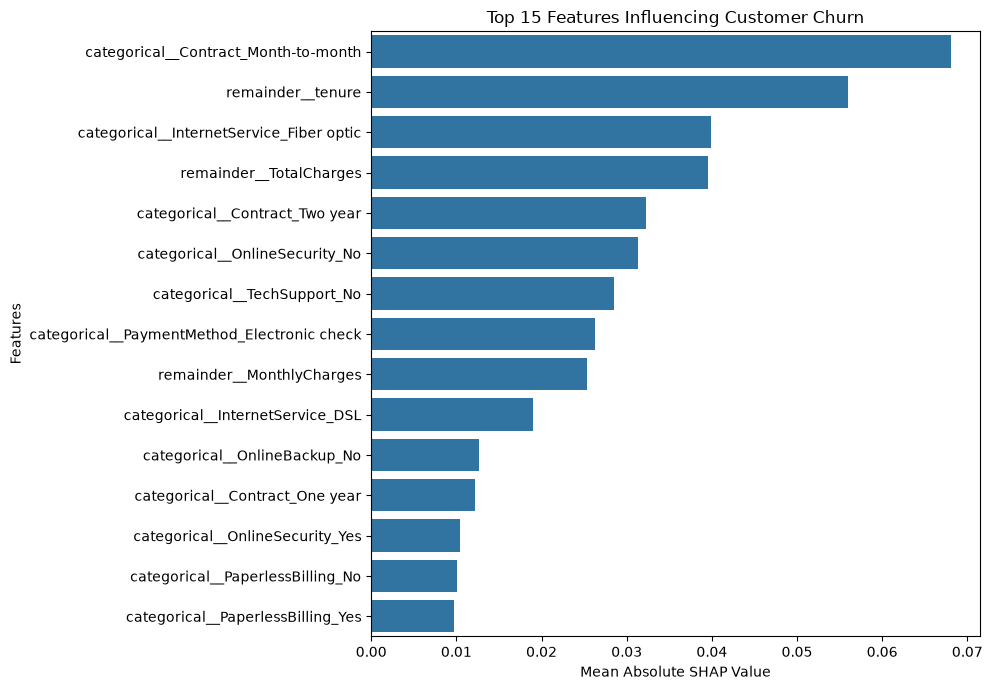

In [118]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=shap_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [119]:
# Generate Random Forest predictions
rf_predictions = random_forest_model.predict(X_test_encoded)

# Find a correctly predicted churned customer
churned_customer = np.where(
    (y_test.to_numpy() == 1) &
    (rf_predictions == 1)
)[0][0]

print("Selected Customer Index:", churned_customer)
print("Actual Churn:", y_test.iloc[churned_customer])
print("Predicted Churn:", rf_predictions[churned_customer])

Selected Customer Index: 9
Actual Churn: 1
Predicted Churn: 1


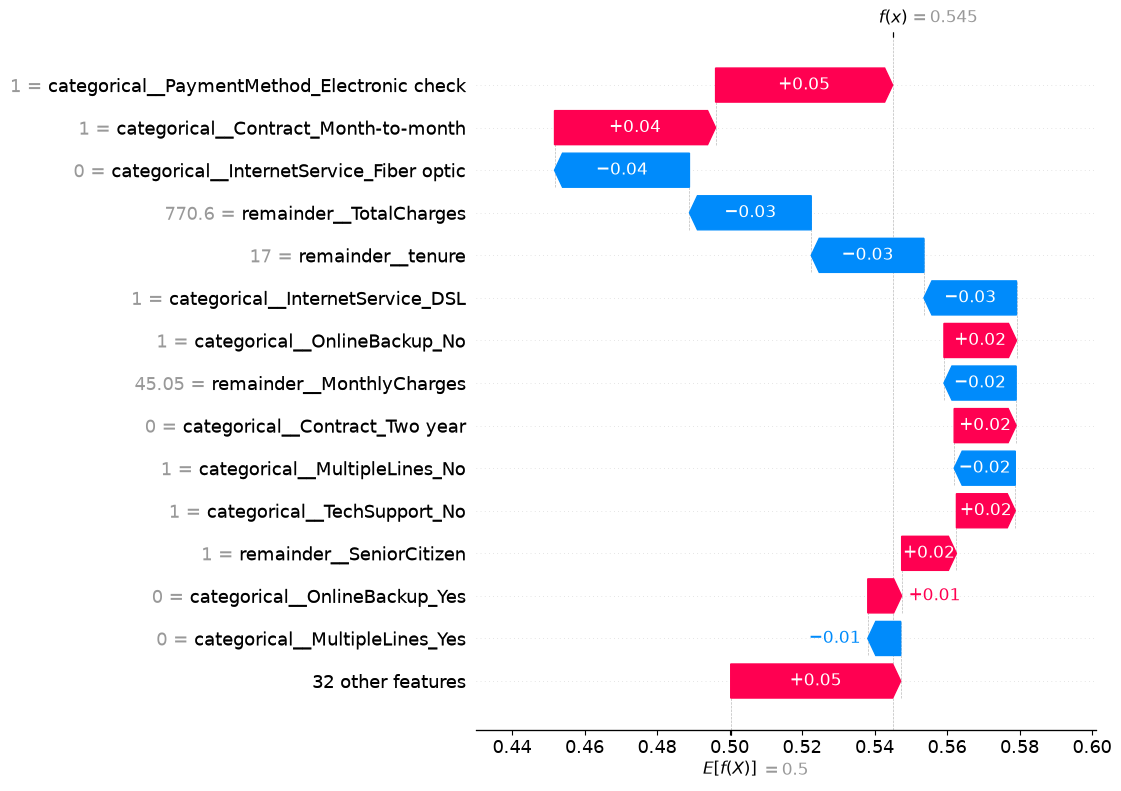

In [120]:
# Get SHAP base value
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

# Create explanation for selected customer
customer_explanation = shap.Explanation(
    values=shap_values_churn[churned_customer],
    base_values=base_value,
    data=X_test_shap.iloc[churned_customer].values,
    feature_names=X_test_shap.columns.tolist()
)

# Generate waterfall plot
shap.plots.waterfall(
    customer_explanation,
    max_display=15
)

## 29. SHAP Analysis – Key Insights

Based on the SHAP Summary Plot, Feature Importance Plot, and Individual Waterfall Plot, the following insights were identified:

1. **Contract Type is the Most Influential Feature:** Month-to-month contracts have the highest SHAP importance (0.0681), indicating that contract type plays a major role in customer churn predictions.

2. **Customer Tenure is Highly Important:** Tenure has the second-highest importance (0.0559). Customers with shorter tenure generally have a higher contribution towards churn predictions, while longer tenure reduces churn risk.

3. **Internet Service Matters:** Fiber optic service has an importance score of 0.0399, showing that internet service type significantly influences churn predictions.

4. **Total Charges Influence Predictions:** Total Charges has an importance score of 0.0395, indicating that customers' accumulated charges contribute to churn prediction.

5. **Long-Term Contracts Reduce Churn Risk:** Two-year contracts have an importance score of 0.0323. The SHAP summary plot indicates that having a two-year contract generally contributes towards lower churn predictions.

6. **Lack of Additional Services:** Online Security (No) and Tech Support (No) have importance scores of 0.0314 and 0.0285, respectively. These features are important factors in the model's churn predictions.

7. **Payment Method Matters:** Electronic Check has an importance score of 0.0263, highlighting the influence of payment method on predicted churn.

### Individual Customer Explanation

The SHAP Waterfall Plot was generated for one correctly predicted churned customer.

- Actual Churn: 1
- Predicted Churn: 1
- Electronic Check contributed positively to the churn prediction.
- Month-to-month contract also increased the predicted churn score.
- Other features, including tenure and internet service indicators, contributed towards or away from the prediction.

### SHAP Analysis Conclusion

The SHAP analysis explains both overall model behaviour and individual customer predictions. Contract type, tenure, internet service, total charges, and additional services emerged as important features influencing churn predictions.

This analysis improves model interpretability and helps identify customer characteristics that can be considered when designing targeted retention strategies.

## 30. Business Recommendations & Customer Retention Action Plan

### Business Insights

Based on the exploratory data analysis and SHAP explainability results, the following business insights were identified:

1. **High Churn Among Month-to-Month Customers:** Month-to-month customers have a churn rate of 42.71%. Contract type is also the most influential feature in SHAP analysis, with an importance score of 0.0681.

2. **New Customers Are More Likely to Churn:** Customers who churned had an average tenure of 17.98 months, compared to 37.57 months for retained customers.

3. **Higher Churn Among Fiber Optic Users:** Fiber optic customers have a churn rate of 41.89%, making this an important segment for further investigation.

4. **Electronic Check Users Have Higher Churn:** Customers using electronic checks have a churn rate of 45.29%, compared to customers using automatic payment methods.

5. **Lack of Support Services:** Customers without Online Security and Tech Support have noticeably higher churn rates than customers subscribed to these services.

6. **Senior Citizens Require Additional Attention:** Senior citizens have a churn rate of 41.68%, compared to 23.61% among non-senior citizens.

7. **Demographic Factors Influence Customer Segments:** Senior citizens without a partner and without dependents have the highest demographic segment churn rate of 49.20%.

### Business Recommendations

Based on the identified churn patterns, the following actions are recommended:

1. **Promote Long-Term Contracts:** Encourage month-to-month customers to switch to one-year or two-year contracts through discounts, loyalty benefits, and flexible subscription offers.

2. **Improve Early Customer Engagement:** Introduce welcome programs, onboarding assistance, and regular follow-ups for new customers during their initial months.

3. **Investigate Fiber Optic Service Issues:** Review service quality, pricing, network reliability, and customer complaints among fiber optic users.

4. **Encourage Automatic Payments:** Offer convenient payment options and incentives to encourage electronic check users to consider automatic payment methods.

5. **Promote Additional Support Services:** Offer affordable Online Security and Tech Support packages to customers who are not subscribed to these services.

6. **Introduce Personalized Retention Programs:** Provide dedicated customer support and suitable service packages for senior citizens and other high-risk demographic segments.

7. **Use Machine Learning for Early Churn Detection:** Apply churn prediction models to identify customers at risk and prioritize them for retention campaigns.

### Expected Business Benefits

- Improved customer retention.
- Reduced customer churn.
- Better customer satisfaction.
- More effective targeted marketing campaigns.
- Data-driven customer retention decisions.
- Better allocation of customer support resources.

## 31. Final Project Conclusion

This project focused on analyzing customer churn patterns and developing a machine learning solution to identify customers who are likely to leave a telecom service.

### Key Findings

1. The dataset showed an overall customer churn rate of 26.54%.
2. Customers with month-to-month contracts demonstrated significantly higher churn than customers with long-term contracts.
3. Customers with shorter tenure and higher monthly charges showed greater churn tendencies.
4. Customers without Online Security and Tech Support services demonstrated higher churn rates.
5. SHAP analysis identified contract type, tenure, internet service, TotalCharges, and additional services as important features influencing model predictions.

### Machine Learning Results

Three machine learning models were evaluated: Logistic Regression, Random Forest, and XGBoost.

Random Forest was selected as the final model because it achieved the highest recall of 62.83% and correctly identified 235 churned customers in the test dataset.

The saved model and preprocessing pipeline were also tested to verify prediction consistency.

### Business Recommendations

Based on the analysis, telecom companies can:

- Encourage month-to-month customers to choose long-term contracts.
- Offer targeted retention campaigns to customers with shorter tenure.
- Improve customer support and online security service adoption.
- Investigate customer dissatisfaction among fiber optic internet users.
- Use churn predictions to prioritize customer retention efforts.

### Final Conclusion

This project demonstrates how Exploratory Data Analysis, Machine Learning, and SHAP explainability can work together to understand customer churn and support data-driven business decisions.

The developed model can help businesses identify potential churners and plan targeted retention strategies. However, model predictions should be evaluated continuously using new customer data before being used in a real business environment.

### 32.1 Loading Cleaned Data into SQLite Database

In this step, the cleaned customer churn dataset is exported from Pandas DataFrame into an SQLite database.

The `sqlite3` library is used to establish a connection with the database, while `pandas` provides the `to_sql()` function to store the dataset in a SQL table.

**Key operations:**
- Connect to the SQLite database.
- Create a table named `customers`.
- Export the cleaned DataFrame into the database.
- Use `if_exists="replace"` to replace the existing table if it already exists.
- Set `index=False` to avoid storing the DataFrame index as an additional column.

The database is saved as `customer_churn.db` in the project root directory.

In [127]:
import sqlite3
import pandas as pd

# Connect to SQLite database
conn = sqlite3.connect("../customer_churn.db")

# Export cleaned dataset to SQL table
df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

print("Customer data successfully loaded into SQLite!")

Customer data successfully loaded into SQLite!


### 32.2 Verifying Data in SQLite Database

After exporting the cleaned dataset, the database table is queried to verify that customer records have been stored correctly.

The `SELECT` statement retrieves the first five records from the `customers` table using the `LIMIT` clause.

In [128]:
query = """
SELECT *
FROM customers
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,3
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,3
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,1


### 32.3 Overall Customer Churn Analysis

The objective of this query is to calculate the total number of customers, the number of churned customers, the number of retained customers, and the overall churn rate.

This analysis provides a high-level understanding of customer retention and churn within the telecom dataset.

In [130]:
query = """
SELECT
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    SUM(CASE WHEN Churn = 0 THEN 1 ELSE 0 END) AS Retained_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers;
"""

pd.read_sql_query(query, conn)

,Total_Customers,Churned_Customers,Retained_Customers,Churn_Rate_Percentage
0,7043,1869,5174,26.54


**Business Insight:**

The telecom company has an overall customer churn rate of 26.54%, meaning approximately one out of every four customers has discontinued the service.

This indicates a significant customer retention challenge. The company should identify high-risk customer segments and develop targeted retention strategies to reduce customer loss.

### 32.4 Customer Churn Analysis by Contract Type

This query analyzes customer churn across different contract types: Month-to-month, One year, and Two year.

The objective is to identify which contract category has the highest churn rate and understand the relationship between contract duration and customer retention.

In [131]:
query = """
SELECT
    Contract,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY Contract
ORDER BY Churn_Rate_Percentage DESC;
"""

pd.read_sql_query(query, conn)

,Contract,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


**Business Insight:**

Month-to-month contract customers have the highest churn rate of 42.71%, while two-year contract customers have the lowest churn rate of 2.83%.

This indicates a strong relationship between contract duration and customer retention. Customers with long-term contracts are more likely to stay with the company.

**Recommendation:** The company should encourage month-to-month customers to switch to one-year or two-year contracts by offering loyalty benefits, discounts, and attractive renewal plans.

### 32.5 Customer Churn Analysis by Tenure Group

This query categorizes customers into different tenure groups based on the number of months they have stayed with the company.

The objective is to identify whether newer customers are more likely to churn compared to long-term customers.

In [132]:
query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 Months'
        WHEN tenure <= 24 THEN '13-24 Months'
        WHEN tenure <= 48 THEN '25-48 Months'
        ELSE '49+ Months'
    END AS Tenure_Group,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY Tenure_Group
ORDER BY MIN(tenure);
"""

pd.read_sql_query(query, conn)

,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,0-12 Months,2186,1037,47.44
1,13-24 Months,1024,294,28.71
2,25-48 Months,1594,325,20.39
3,49+ Months,2239,213,9.51


**Business Insight:**

Customers who have stayed with the company for 0–12 months have the highest churn rate of 47.44%. In comparison, customers with 49+ months of tenure have the lowest churn rate of 9.51%.

The analysis indicates that newer customers are more likely to leave, while long-term customers demonstrate stronger loyalty.

**Recommendation:** The company should focus on improving the onboarding experience, providing early-stage customer support, and offering special incentives during the first year to improve customer retention.

### 32.6 Customer Churn Analysis by Payment Method

This analysis compares customer counts and churn rates across payment methods. The results can help determine whether payment behavior is associated with different retention outcomes.

In [133]:
query = """
SELECT
    PaymentMethod,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY PaymentMethod
ORDER BY Churn_Rate_Percentage DESC, Total_Customers DESC;
"""

pd.read_sql_query(query, conn)

,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


**Business Insight:**
Customers using Electronic Check have the highest churn rate of 45.29%. In comparison, customers using Credit Card (Automatic) have the lowest churn rate of 15.24%.

The analysis indicates that customers using electronic check payments are more likely to leave the company compared to customers using automatic payment methods.

**Recommendation:**
The company should encourage customers to switch to automatic payment methods by offering convenient payment options, incentives, and simplified payment setup. It should also investigate possible billing or payment-related issues experienced by electronic check users.

### 32.7 Customer Churn Analysis by Internet Service

This query evaluates churn across internet service types. Comparing churn rates across service groups helps identify customer experiences that may require targeted retention support.

In [134]:
query = """
SELECT
    InternetService,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY InternetService
ORDER BY Churn_Rate_Percentage DESC, Total_Customers DESC;
"""

pd.read_sql_query(query, conn)

,InternetService,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


**Business Insight:**
Fiber Optic customers have the highest churn rate of 41.89%, while DSL customers have a churn rate of 18.96%. Customers without internet service have the lowest churn rate of 7.40%.

The analysis indicates that Fiber Optic customers are more likely to leave the company compared to other internet service categories.

**Recommendation:**
The company should investigate fiber optic service quality, pricing, and customer satisfaction. Improving service reliability, resolving technical issues, and offering competitive pricing plans may help improve customer retention.

### 32.8 Customer Churn Analysis by Online Security

This analysis compares churn for each recorded OnlineSecurity category, including customers with no internet service. It helps assess whether security-service adoption is associated with retention.

In [135]:
query = """
SELECT
    OnlineSecurity,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY OnlineSecurity
ORDER BY Churn_Rate_Percentage DESC, Total_Customers DESC;
"""

pd.read_sql_query(query, conn)

,OnlineSecurity,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,No,3498,1461,41.77
1,Yes,2019,295,14.61
2,No internet service,1526,113,7.40


**Business Insight:&#x20;**&#x43;ustomers without Online Security have the highest churn rate of 41.77%. In comparison, customers subscribed to Online Security have a churn rate of 14.61%.

The analysis indicates that customers without Online Security are more likely to leave the company, while customers using this service demonstrate better retention.

**Recommendation:**&#x54;he company should encourage customers to subscribe to Online Security by offering attractive service bundles, introductory discounts, and awareness about the benefits of online protection.


### 32.9 Customer Churn Analysis by Tech Support

This query measures churn among customers in each TechSupport category, including customers without internet service. The comparison can help evaluate the relationship between support coverage and retention.

In [136]:
query = """
SELECT
    TechSupport,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY TechSupport
ORDER BY Churn_Rate_Percentage DESC, Total_Customers DESC;
"""

pd.read_sql_query(query, conn)

,TechSupport,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,No,3473,1446,41.64
1,Yes,2044,310,15.17
2,No internet service,1526,113,7.40


**Business Insight:**
Customers without Tech Support have the highest churn rate of 41.64%, while customers subscribed to Tech Support have a churn rate of 15.17%.

The analysis indicates that customers with access to technical support demonstrate better retention compared to customers without this service.

**Recommendation:**
The company should improve technical support accessibility, provide faster issue resolution, and encourage customers to subscribe to Tech Support through suitable service packages.


### 32.10 Monthly Charges Analysis by Churn Status

This analysis compares customer counts and monthly-charge distributions for retained and churned customers. Average and range statistics provide a distinct view of the monthly billing level associated with each outcome.

In [137]:
query = """
SELECT
    CASE WHEN Churn = 1 THEN 'Churned' ELSE 'Retained' END AS Churn_Status,
    COUNT(*) AS Total_Customers,
    ROUND(AVG(MonthlyCharges), 2) AS Average_Monthly_Charges,
    ROUND(MIN(MonthlyCharges), 2) AS Minimum_Monthly_Charges,
    ROUND(MAX(MonthlyCharges), 2) AS Maximum_Monthly_Charges
FROM customers
GROUP BY Churn
ORDER BY Churn DESC;
"""

pd.read_sql_query(query, conn)

,Churn_Status,Total_Customers,Average_Monthly_Charges,Minimum_Monthly_Charges,Maximum_Monthly_Charges
0,Churned,1869,74.44,18.85,118.35
1,Retained,5174,61.27,18.25,118.75


**Business Insight:**
Churned customers have an average monthly charge of $74.44, compared to $61.27 for retained customers.

The analysis indicates that customers paying higher monthly charges may be more likely to leave the company, suggesting a possible relationship between billing levels and customer churn.

**Recommendation:**
The company should review pricing plans, provide suitable discounts to high-billing customers, and introduce personalized service bundles to improve customer satisfaction and reduce churn.

### 32.11 Customer Churn Analysis by Senior Citizen Status

This query compares customer counts and churn rates for senior and non-senior customers. The results show whether retention outcomes differ across these two customer groups.

In [138]:
query = """
SELECT
    CASE WHEN SeniorCitizen = 1 THEN 'Senior Citizen' ELSE 'Non-Senior Citizen' END AS Senior_Citizen_Status,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY SeniorCitizen
ORDER BY SeniorCitizen;
"""

pd.read_sql_query(query, conn)

,Senior_Citizen_Status,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,Non-Senior Citizen,5901,1393,23.61
1,Senior Citizen,1142,476,41.68


**Business Insight:**
Senior citizens have the highest churn rate of 41.68%, while non-senior citizens have a churn rate of 23.61%.

The analysis indicates that senior customers are more likely to leave the company compared to non-senior customers.

**Recommendation:**
The company should provide accessible customer support, simple subscription plans, and personalized assistance to senior customers to improve their overall experience and encourage long-term retention.

### 32.12 Customer Churn Analysis by Partner and Dependents

This analysis groups customers by the combination of Partner and Dependents status. Comparing these household segments helps identify differences in churn that may not be visible when each attribute is considered alone.

In [139]:
query = """
SELECT
    Partner,
    Dependents,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage
FROM customers
GROUP BY Partner, Dependents
ORDER BY Churn_Rate_Percentage DESC, Total_Customers DESC;
"""

pd.read_sql_query(query, conn)

,Partner,Dependents,Total_Customers,Churned_Customers,Churn_Rate_Percentage
0,No,No,3280,1123,34.24
1,Yes,No,1653,420,25.41
2,No,Yes,361,77,21.33
3,Yes,Yes,1749,249,14.24


**Business Insight:**
Customers without a partner and without dependents have the highest churn rate of 34.24%. In comparison, customers with both a partner and dependents have the lowest churn rate of 14.24%.

The analysis indicates that customers with family responsibilities demonstrate better retention compared to customers without partners or dependents.

**Recommendation:**
The company should focus on customers without partners or dependents by offering personalized service plans, loyalty benefits, and targeted retention campaigns to improve customer engagement.

### 32.13 High-Risk Customer Segment Analysis

This query measures churn for a clearly defined composite segment: month-to-month customers with 12 months or less of tenure who pay by electronic check. It compares this group with all other customers to quantify the segment-level risk.

In [140]:
query = """
SELECT
    CASE
        WHEN Contract = 'Month-to-month'
         AND tenure <= 12
         AND PaymentMethod = 'Electronic check'
        THEN 'High-Risk Segment'
        ELSE 'Other Customers'
    END AS Customer_Segment,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*),
        2
    ) AS Churn_Rate_Percentage,
    ROUND(AVG(MonthlyCharges), 2) AS Average_Monthly_Charges
FROM customers
GROUP BY Customer_Segment
ORDER BY CASE WHEN Customer_Segment = 'High-Risk Segment' THEN 0 ELSE 1 END;
"""

pd.read_sql_query(query, conn)

,Customer_Segment,Total_Customers,Churned_Customers,Churn_Rate_Percentage,Average_Monthly_Charges
0,High-Risk Segment,954,602,63.10,69.26
1,Other Customers,6089,1267,20.81,64.06


**Business Insight:**
The defined high-risk customer segment, consisting of month-to-month customers with tenure of 12 months or less who use electronic check payments, has a churn rate of 63.10%. In comparison, other customers have a churn rate of 20.81%.

The analysis indicates that the combination of short customer tenure, month-to-month contracts, and electronic check payments identifies a customer segment with significantly higher churn.

**Recommendation:**
The company should prioritize this high-risk segment by offering long-term contract incentives, improving early-stage customer support, encouraging automatic payment methods, and providing personalized retention offers.

### 32.14 Customer Revenue Analysis

This analysis compares the monthly charges and accumulated TotalCharges of retained and churned customers. The sums are descriptive billing measures for this dataset and are not an estimate of recoverable revenue.

In [141]:
query = """
SELECT
    CASE WHEN Churn = 1 THEN 'Churned' ELSE 'Retained' END AS Churn_Status,
    COUNT(*) AS Total_Customers,
    ROUND(SUM(MonthlyCharges), 2) AS Sum_of_Monthly_Charges,
    ROUND(AVG(MonthlyCharges), 2) AS Average_Monthly_Charges,
    ROUND(SUM(TotalCharges), 2) AS Sum_of_Historical_Total_Charges
FROM customers
GROUP BY Churn
ORDER BY Churn DESC;
"""

pd.read_sql_query(query, conn)

,Churn_Status,Total_Customers,Sum_of_Monthly_Charges,Average_Monthly_Charges,Sum_of_Historical_Total_Charges
0,Churned,1869,139130.85,74.44,2862926.90
1,Retained,5174,316985.75,61.27,13208614.03


**Business Insight:**
Churned customers contribute combined monthly charges of $139,130.85, while retained customers contribute $316,985.75. Additionally, churned customers have a higher average monthly charge of $74.44 compared to $61.27 for retained customers.

The analysis highlights the billing value associated with customers who have discontinued their services and the importance of retaining high-value customers.

**Recommendation:**
The company should identify customers with higher monthly charges and provide suitable pricing plans, personalized discounts, and service bundles. Targeted retention strategies can help reduce customer loss and protect recurring monthly billing.

### 32.15 Final SQL Business Insights

This summary query brings together the overall churn rate and selected churn rates for major customer segments analyzed above. It provides a concise, database-derived basis for the final SQL takeaways.

In [142]:
query = """
SELECT
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(SUM(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / COUNT(*), 2) AS Overall_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN Contract = 'Month-to-month' AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN Contract = 'Month-to-month' THEN 1 ELSE 0 END), 0), 2) AS Month_to_month_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN tenure <= 12 AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN tenure <= 12 THEN 1 ELSE 0 END), 0), 2) AS First_12_Months_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN PaymentMethod = 'Electronic check' AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN PaymentMethod = 'Electronic check' THEN 1 ELSE 0 END), 0), 2) AS Electronic_Check_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN InternetService = 'Fiber optic' AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN InternetService = 'Fiber optic' THEN 1 ELSE 0 END), 0), 2) AS Fiber_Optic_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN OnlineSecurity = 'No' AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN OnlineSecurity = 'No' THEN 1 ELSE 0 END), 0), 2) AS No_Online_Security_Churn_Rate_Percentage,
    ROUND(SUM(CASE WHEN TechSupport = 'No' AND Churn = 1 THEN 1.0 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN TechSupport = 'No' THEN 1 ELSE 0 END), 0), 2) AS No_Tech_Support_Churn_Rate_Percentage,
    ROUND(AVG(CASE WHEN Churn = 1 THEN MonthlyCharges END), 2) AS Churned_Average_Monthly_Charges,
    ROUND(AVG(CASE WHEN Churn = 0 THEN MonthlyCharges END), 2) AS Retained_Average_Monthly_Charges
FROM customers;
"""

pd.read_sql_query(query, conn)

,Total_Customers,Churned_Customers,Overall_Churn_Rate_Percentage,Month_to_month_Churn_Rate_Percentage,First_12_Months_Churn_Rate_Percentage,Electronic_Check_Churn_Rate_Percentage,Fiber_Optic_Churn_Rate_Percentage,No_Online_Security_Churn_Rate_Percentage,No_Tech_Support_Churn_Rate_Percentage,Churned_Average_Monthly_Charges,Retained_Average_Monthly_Charges
0,7043,1869,26.54,42.71,47.44,45.29,41.89,41.77,41.64,74.44,61.27


**Business Insight:**
The SQL analysis identifies several customer segments associated with higher churn, including month-to-month contract customers, customers with shorter tenure, electronic check users, and customers without Online Security or Tech Support.

The analysis also identifies a defined high-risk customer segment with a churn rate of 63.10%, compared to 20.81% among other customers.

**Recommendation:**
The company should focus on early customer engagement, promote long-term contracts, improve service quality, encourage automatic payment methods, and provide targeted retention offers to high-risk customers. Regular monitoring of churn patterns can help the business improve customer loyalty and make data-driven retention decisions.